# Week 10: learning a one-dimensional approximately ancillary statistic



$$
y^{(1)}=y, \qquad y^{(2)}=2y.
$$

Both members of a pair belong to the same model family but correspond to different parameter values. The same Week 7 CNN, with shared weights, maps both inputs to a scalar statistic $s(y)$. The classifier is deliberately built only from this scalar bottleneck, so a constant statistic cannot classify the three models.

The training objective is

$$
L=\frac{CE(M,\widehat M_y)+CE(M,\widehat M_{2y})}{2}
+0.5\,\operatorname{MSE}\{s(y),s(2y)\}.
$$

The parameter $\theta$ is retained only for diagnostics; it is not a training target. This is an experiment in approximate parameter invariance, not a proof of exact ancillarity.

## 1. Imports and reproducibility

In [27]:
from pathlib import Path
import os
import random

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/mpl-scdl3991-week10")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, r2_score
from sklearn.model_selection import train_test_split
from scipy.stats import spearmanr

SEED = 3991
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

MODEL_NAMES = np.array(["Exponential", "Log-normal", "Gamma"])
SAMPLE_SIZE = 100
N_PER_MODEL = 3_000
N_DATASETS = 3 * N_PER_MODEL
EPOCHS = 40
BATCH_SIZE = 256
LAMBDA_STAT = 0.5

BASE_DIR = Path.cwd()
if BASE_DIR.name != "week10" and (BASE_DIR / "week10").is_dir():
    BASE_DIR = BASE_DIR / "week10"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print(f"Base simulations: {N_DATASETS:,}; observations per dataset: {SAMPLE_SIZE}")
print("Output directory:", OUTPUT_DIR.resolve())

TensorFlow: 2.21.0
Base simulations: 9,000; observations per dataset: 100
Output directory: /Users/selinalu/Desktop/scdl3991/week10/outputs


## 2. Simulate once and construct the paired view

The candidate models and priors match the earlier notebooks:

- $M_1$: Exponential(rate $\theta$), $\theta\sim\mathrm{Exp}(1)$;
- $M_2$: Log-normal(location $\theta$, scale 1), $\theta\sim N(0,1)$;
- $M_3$: Gamma(shape 2, rate $\theta$), $\theta\sim\mathrm{Exp}(1)$.

The raw pair is constructed as $(y,2y)$, not by a second random simulation. Multiplication by two preserves the family and changes the effective parameter:

$$
\theta^*=\theta/2\quad\text{for Exponential and Gamma rates},
\qquad
\theta^*=\theta+\log 2\quad\text{for the Log-normal location}.
$$

Why the rate is divided by two: a rate is the inverse of scale. For an Exponential variable,

$$
P(2Y>t)=P(Y>t/2)=\exp(-\theta t/2)
=\exp\{-(\theta/2)t\},
$$

so $2Y$ has rate $\theta/2$, not $2\theta$. The same scale-rate relationship applies to the Gamma model when its shape is fixed.

For the Log-normal model, $\log Y\sim N(\theta,1)$. Therefore,

$$
\log(2Y)=\log 2+\log Y\sim N(\theta+\log 2,1),
$$

which explains the addition of $\log 2$ to the log-location parameter.


In [28]:
rng = np.random.default_rng(SEED)

theta_exp = rng.exponential(scale=1.0, size=N_PER_MODEL)
theta_logn = rng.normal(loc=0.0, scale=1.0, size=N_PER_MODEL)
theta_gamma = rng.exponential(scale=1.0, size=N_PER_MODEL)

exp_samples = rng.exponential(
    scale=1.0 / np.clip(theta_exp[:, None], 1e-6, None),
    size=(N_PER_MODEL, SAMPLE_SIZE),
)
logn_samples = rng.lognormal(
    mean=theta_logn[:, None], sigma=1.0,
    size=(N_PER_MODEL, SAMPLE_SIZE),
)
gamma_samples = rng.gamma(
    shape=2.0,
    scale=1.0 / np.clip(theta_gamma[:, None], 1e-6, None),
    size=(N_PER_MODEL, SAMPLE_SIZE),
)

X_raw = np.vstack([exp_samples, logn_samples, gamma_samples]).astype("float32")
X_raw_doubled = (2.0 * X_raw).astype("float32")
y_model = np.repeat(np.arange(3), N_PER_MODEL).astype("int32")
y_onehot = keras.utils.to_categorical(y_model, num_classes=3).astype("float32")
theta = np.concatenate([theta_exp, theta_logn, theta_gamma]).astype("float32")

# Same Week 7 transformation for both views; no fitted standardization.
X_original = np.arcsinh(X_raw)[..., None].astype("float32")
X_doubled = np.arcsinh(X_raw_doubled)[..., None].astype("float32")

assert np.allclose(X_raw_doubled, 2.0 * X_raw)
print("Original input:", X_original.shape)
print("Doubled input: ", X_doubled.shape)
print("Class target:  ", y_onehot.shape)
print("Theta:         ", theta.shape)

Original input: (9000, 100, 1)
Doubled input:  (9000, 100, 1)
Class target:   (9000, 3)
Theta:          (9000,)


## 3. Split base simulations before training

The original and doubled versions of a dataset always remain in the same split. This prevents paired-data leakage. The split is 64% training, 16% validation, and 20% testing, stratified by model.

In [29]:
all_idx = np.arange(N_DATASETS)
train_val_idx, test_idx = train_test_split(
    all_idx, test_size=0.20, random_state=SEED, stratify=y_model
)
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.20,
    random_state=SEED + 1,
    stratify=y_model[train_val_idx],
)

print("Train / validation / test:", len(train_idx), len(val_idx), len(test_idx))
print("Pairs remain intact because indices are split before either view is selected.")

Train / validation / test: 5760 1440 1800
Pairs remain intact because indices are split before either view is selected.


## 4. Shared Week 7 CNN with a scalar bottleneck

The convolutional feature extractor is unchanged:

$$
100\rightarrow\mathrm{Conv1D}(32)\rightarrow\mathrm{MaxPool}
\rightarrow\mathrm{Conv1D}(64)\rightarrow\mathrm{GlobalAveragePool}\rightarrow64.
$$

A linear $64\to1$ layer produces the learned statistic. The model classifier receives **only** this one-dimensional statistic. The same network object is called on both inputs, which guarantees shared weights.

In [30]:
def build_shared_cnn():
    inputs = keras.Input(shape=(SAMPLE_SIZE, 1), name="dataset")
    x = layers.Conv1D(32, kernel_size=5, padding="same", activation="relu", name="conv_1")(inputs)
    x = layers.MaxPooling1D(pool_size=2, name="max_pool")(x)
    x = layers.Conv1D(64, kernel_size=5, padding="same", activation="relu", name="conv_2")(x)
    x = layers.GlobalAveragePooling1D(name="global_average_pool")(x)
    embedding = layers.Dense(64, activation="relu", name="learned_embedding")(x)
    statistic = layers.Dense(1, activation="linear", name="statistic")(embedding)

    # A small nonlinear head lets three classes use a one-dimensional coordinate.
    class_hidden = layers.Dense(24, activation="elu", name="class_hidden")(statistic)
    class_output = layers.Dense(3, activation="softmax", name="class_output")(class_hidden)
    return keras.Model(
        inputs,
        {"class_output": class_output, "statistic": statistic},
        name="shared_week7_cnn",
    )


shared_cnn = build_shared_cnn()

original_input = keras.Input(shape=(SAMPLE_SIZE, 1), name="original_dataset")
doubled_input = keras.Input(shape=(SAMPLE_SIZE, 1), name="doubled_dataset")
original_outputs = shared_cnn(original_input)
doubled_outputs = shared_cnn(doubled_input)

class_original = layers.Activation("linear", name="class_original")(
    original_outputs["class_output"]
)
class_doubled = layers.Activation("linear", name="class_doubled")(
    doubled_outputs["class_output"]
)
stat_difference = layers.Subtract(name="stat_difference")([
    original_outputs["statistic"], doubled_outputs["statistic"]
])

paired_model = keras.Model(
    inputs={"original_dataset": original_input, "doubled_dataset": doubled_input},
    outputs={
        "class_original": class_original,
        "class_doubled": class_doubled,
        "stat_difference": stat_difference,
    },
    name="paired_ancillary_cnn",
)

paired_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=5.0),
    loss={
        "class_original": "categorical_crossentropy",
        "class_doubled": "categorical_crossentropy",
        "stat_difference": "mse",
    },
    loss_weights={
        "class_original": 0.5,
        "class_doubled": 0.5,
        "stat_difference": LAMBDA_STAT,
    },
    metrics={
        "class_original": ["accuracy"],
        "class_doubled": ["accuracy"],
        "stat_difference": ["mse"],
    },
)

paired_model.summary()
print("Learned statistic dimension:", shared_cnn.get_layer("statistic").units)

Model: "paired_ancillary_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ doubled_dataset     │ (None, 100, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ original_dataset    │ (None, 100, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_week7_cnn    │ [(None, 3),       │     14,844 │ original_dataset… │
│ (Functional)        │ (None, 1)]        │            │ doubled_dataset[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_doubled       │ (None, 3)         │          0 │ shared_week7_cnn… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_original      │ (None, 3)         │          0 │ shared_week7_cnn… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stat_difference     │ (None, 1)         │          0 │ shared_week7_cnn… │
│ (Subtract)          │                   │            │ shared_week7_cnn… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,844 (57.98 KB)

 Trainable params: 14,844 (57.98 KB)

 Non-trainable params: 0 (0.00 B)

Learned statistic dimension: 1


## 5. Train one model with $\lambda=0.5$

The zero target for `stat_difference` makes its MSE equal to $\operatorname{MSE}\{s(y),s(2y)\}$.

In [31]:
def paired_inputs(idx):
    return {
        "original_dataset": X_original[idx],
        "doubled_dataset": X_doubled[idx],
    }


def paired_targets(idx):
    return {
        "class_original": y_onehot[idx],
        "class_doubled": y_onehot[idx],
        "stat_difference": np.zeros((len(idx), 1), dtype="float32"),
    }


callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
    ),
]

history = paired_model.fit(
    paired_inputs(train_idx),
    paired_targets(train_idx),
    validation_data=(paired_inputs(val_idx), paired_targets(val_idx)),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=2,
)

history_df = pd.DataFrame(history.history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
print("Completed epochs:", len(history_df))

Epoch 1/40
23/23 - 1s - 44ms/step - class_doubled_accuracy: 0.4587 - class_doubled_loss: 1.0449 - class_original_accuracy: 0.4528 - class_original_loss: 1.0540 - loss: 1.0579 - stat_difference_loss: 0.0152 - stat_difference_mse: 0.0146 - val_class_doubled_accuracy: 0.5201 - val_class_doubled_loss: 0.9738 - val_class_original_accuracy: 0.4819 - val_class_original_loss: 0.9978 - val_loss: 1.0095 - val_stat_difference_loss: 0.0483 - val_stat_difference_mse: 0.0483 - learning_rate: 0.0010
Epoch 2/40
23/23 - 0s - 6ms/step - class_doubled_accuracy: 0.5177 - class_doubled_loss: 0.9359 - class_original_accuracy: 0.4892 - class_original_loss: 0.9613 - loss: 0.9809 - stat_difference_loss: 0.0626 - stat_difference_mse: 0.0626 - val_class_doubled_accuracy: 0.5382 - val_class_doubled_loss: 0.8978 - val_class_original_accuracy: 0.5660 - val_class_original_loss: 0.9178 - val_loss: 0.9377 - val_stat_difference_loss: 0.0622 - val_stat_difference_mse: 0.0622 - learning_rate: 0.0010
Epoch 3/40
23/23 - 0s

## 6. Training curves

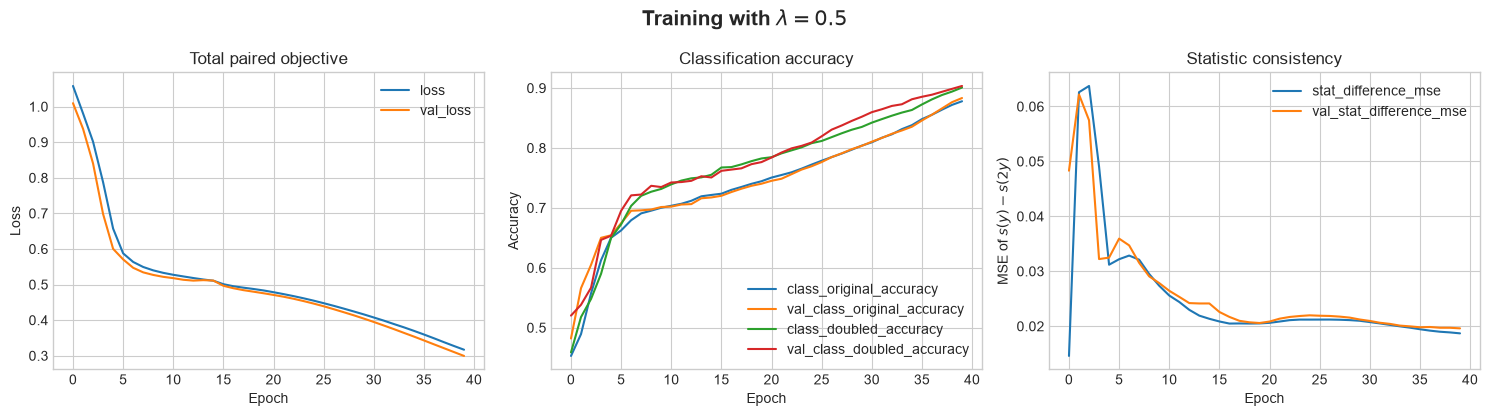

In [32]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

history_df[["loss", "val_loss"]].plot(ax=axes[0], title="Total paired objective")
history_df[["class_original_accuracy", "val_class_original_accuracy",
            "class_doubled_accuracy", "val_class_doubled_accuracy"]].plot(
    ax=axes[1], title="Classification accuracy"
)
history_df[["stat_difference_mse", "val_stat_difference_mse"]].plot(
    ax=axes[2], title="Statistic consistency"
)
axes[0].set_ylabel("Loss")
axes[1].set_ylabel("Accuracy")
axes[2].set_ylabel(r"MSE of $s(y)-s(2y)$")
for ax in axes:
    ax.set_xlabel("Epoch")
fig.suptitle(r"Training with $\lambda=0.5$", fontsize=15, weight="bold")
fig.tight_layout()
plt.show()

## 7. Held-out model classification and paired invariance

The first diagnostic checks whether both views retain model information. The second checks the direct training goal: points should lie near the diagonal in a plot of $s(y)$ against $s(2y)$.

In [33]:
test_scores = paired_model.evaluate(
    paired_inputs(test_idx), paired_targets(test_idx),
    batch_size=BATCH_SIZE, verbose=0, return_dict=True,
)

pred_original = shared_cnn.predict(X_original[test_idx], batch_size=BATCH_SIZE, verbose=0)
pred_doubled = shared_cnn.predict(X_doubled[test_idx], batch_size=BATCH_SIZE, verbose=0)

prob_original = pred_original["class_output"]
prob_doubled = pred_doubled["class_output"]
stat_original = pred_original["statistic"].ravel()
stat_doubled = pred_doubled["statistic"].ravel()
true_test = y_model[test_idx]

class_original_pred = prob_original.argmax(axis=1)
class_doubled_pred = prob_doubled.argmax(axis=1)
accuracy_original = accuracy_score(true_test, class_original_pred)
accuracy_doubled = accuracy_score(true_test, class_doubled_pred)
paired_mse = float(np.mean((stat_original - stat_doubled) ** 2))
paired_mae = float(np.mean(np.abs(stat_original - stat_doubled)))
paired_corr = float(np.corrcoef(stat_original, stat_doubled)[0, 1])

headline = pd.DataFrame([{
    "lambda": LAMBDA_STAT,
    "classification_accuracy_original": accuracy_original,
    "classification_accuracy_doubled": accuracy_doubled,
    "paired_statistic_mse": paired_mse,
    "paired_statistic_mae": paired_mae,
    "paired_statistic_correlation": paired_corr,
}])
headline.to_csv(OUTPUT_DIR / "headline_metrics.csv", index=False)
headline

,lambda,classification_accuracy_original,classification_accuracy_doubled,paired_statistic_mse,paired_statistic_mae,paired_statistic_correlation
0,0.5,0.874444,0.892222,0.017833,0.107792,0.993363


### Primary invariance check: are the paired statistics similar?

This is the direct check of the new objective, before looking at classification. For every held-out pair, compute

$$
\Delta s=s(2y)-s(y).
$$

If the statistic depends mainly on the model rather than the factor-of-two change in values, these differences should be concentrated close to zero. The table reports the error separately for each model.

,model,mean_signed_difference,mean_absolute_difference,root_mean_squared_difference,correlation_s_y_s_2y
0,Exponential,-0.0805,0.1097,0.1349,0.9636
1,Log-normal,0.0856,0.1236,0.1484,0.9411
2,Gamma,0.0618,0.0901,0.1153,0.9809


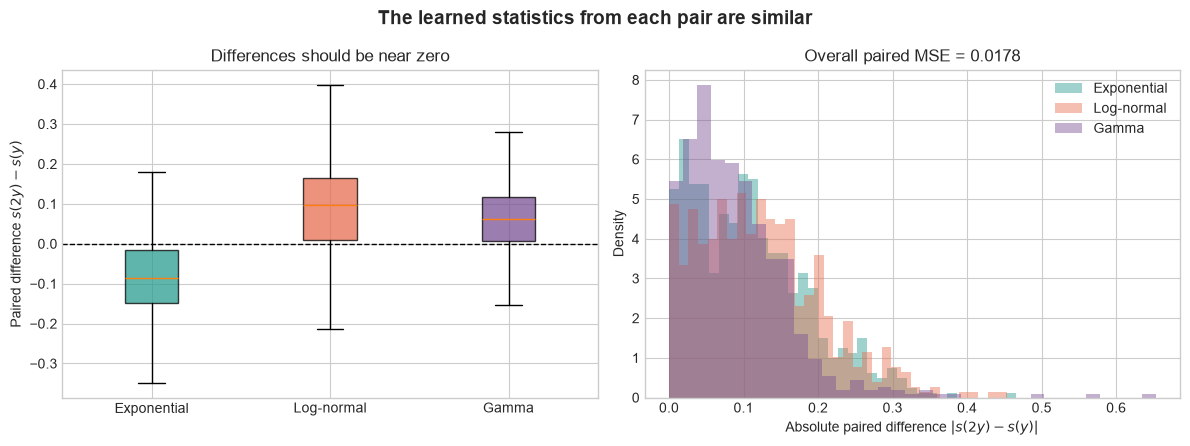

In [34]:
stat_difference_test = stat_doubled - stat_original

pair_rows = []
for model_id, model_name in enumerate(MODEL_NAMES):
    mask = true_test == model_id
    difference = stat_difference_test[mask]
    pair_rows.append({
        "model": model_name,
        "mean_signed_difference": float(np.mean(difference)),
        "mean_absolute_difference": float(np.mean(np.abs(difference))),
        "root_mean_squared_difference": float(np.sqrt(np.mean(difference ** 2))),
        "correlation_s_y_s_2y": float(np.corrcoef(
            stat_original[mask], stat_doubled[mask]
        )[0, 1]),
    })

pair_similarity = pd.DataFrame(pair_rows)
pair_similarity.to_csv(OUTPUT_DIR / "paired_statistic_similarity_by_model.csv", index=False)
display(pair_similarity.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colours = ["#2A9D8F", "#E76F51", "#7A5195"]

box_data = [stat_difference_test[true_test == model_id] for model_id in range(3)]
boxes = axes[0].boxplot(
    box_data, tick_labels=MODEL_NAMES, patch_artist=True, showfliers=False
)
for patch, colour in zip(boxes["boxes"], colours):
    patch.set_facecolor(colour)
    patch.set_alpha(0.75)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(
    ylabel=r"Paired difference $s(2y)-s(y)$",
    title="Differences should be near zero",
)

for model_id, (model_name, colour) in enumerate(zip(MODEL_NAMES, colours)):
    mask = true_test == model_id
    axes[1].hist(
        np.abs(stat_difference_test[mask]), bins=35, density=True,
        alpha=0.45, color=colour, label=model_name,
    )
axes[1].set(
    xlabel=r"Absolute paired difference $|s(2y)-s(y)|$",
    ylabel="Density",
    title=f"Overall paired MSE = {paired_mse:.4f}",
)
axes[1].legend()
fig.suptitle("The learned statistics from each pair are similar", fontsize=14, weight="bold")
fig.tight_layout()
plt.show()

### Model-classification check

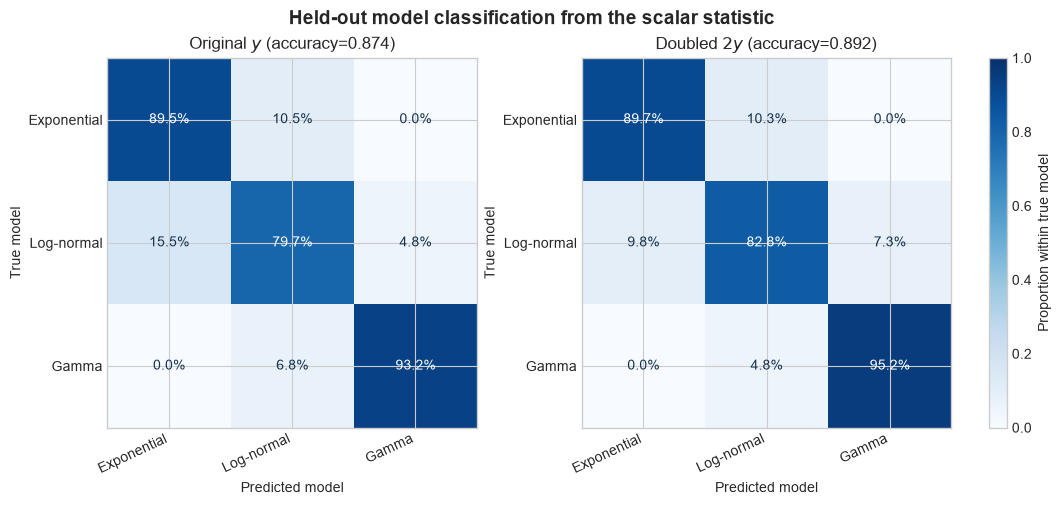

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, predicted, title in zip(
    axes,
    [class_original_pred, class_doubled_pred],
    [f"Original $y$ (accuracy={accuracy_original:.3f})",
     f"Doubled $2y$ (accuracy={accuracy_doubled:.3f})"],
):
    matrix = confusion_matrix(true_test, predicted, labels=[0, 1, 2], normalize="true")
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(3), MODEL_NAMES, rotation=25, ha="right")
    ax.set_yticks(range(3), MODEL_NAMES)
    ax.set_xlabel("Predicted model")
    ax.set_ylabel("True model")
    for row in range(3):
        for col in range(3):
            colour = "white" if matrix[row, col] > 0.5 else "#16324F"
            ax.text(col, row, f"{matrix[row, col]:.1%}", ha="center", va="center", color=colour)
fig.colorbar(image, ax=axes, fraction=0.025, pad=0.04, label="Proportion within true model")
fig.suptitle("Held-out model classification from the scalar statistic", fontsize=14, weight="bold")
plt.show()

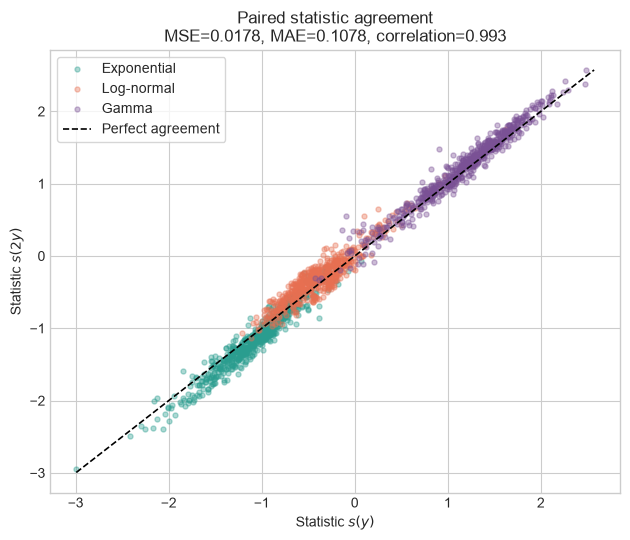

In [36]:
fig, ax = plt.subplots(figsize=(6.4, 5.5))
colours = ["#2A9D8F", "#E76F51", "#7A5195"]
for model_id, (name, colour) in enumerate(zip(MODEL_NAMES, colours)):
    mask = true_test == model_id
    ax.scatter(
        stat_original[mask], stat_doubled[mask],
        s=13, alpha=0.38, color=colour, label=name,
    )
lo = float(min(stat_original.min(), stat_doubled.min()))
hi = float(max(stat_original.max(), stat_doubled.max()))
ax.plot([lo, hi], [lo, hi], "k--", lw=1.2, label="Perfect agreement")
ax.set(
    xlabel=r"Statistic $s(y)$",
    ylabel=r"Statistic $s(2y)$",
    title=(f"Paired statistic agreement\nMSE={paired_mse:.4f}, "
           f"MAE={paired_mae:.4f}, correlation={paired_corr:.3f}"),
)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

## 8. Relationship between $\theta$ and the learned statistic

These plots use the original view and are separated by the true model. A strong monotone pattern would indicate parameter leakage. Spearman correlation is reported descriptively, and a fresh nonlinear Extra Trees probe tests how well $\theta$ can be recovered from the one-dimensional statistic. Lower probe $R^2$ is better for the invariance goal.

This diagnostic does not standardize $\theta$, and $\theta$ never enters the training loss.

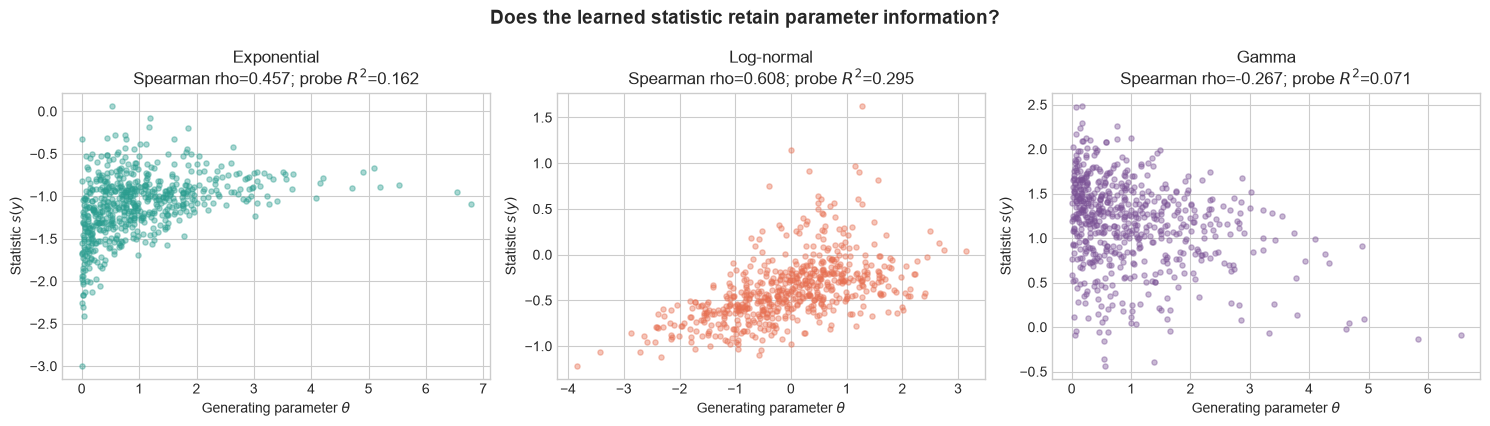

,model,spearman_rho_theta_statistic,spearman_p_value,theta_probe_r2
0,Exponential,0.456936,2.753960e-32,0.161934
1,Log-normal,0.608006,6.291950e-62,0.295104
2,Gamma,-0.266969,2.996138e-11,0.071295


In [37]:
train_pred = shared_cnn.predict(X_original[train_idx], batch_size=BATCH_SIZE, verbose=0)
stat_train = train_pred["statistic"].ravel()

relationship_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for model_id, (name, colour, ax) in enumerate(zip(MODEL_NAMES, colours, axes)):
    train_mask = y_model[train_idx] == model_id
    test_mask = true_test == model_id
    theta_test_model = theta[test_idx][test_mask]
    stat_test_model = stat_original[test_mask]

    rho, p_value = spearmanr(theta_test_model, stat_test_model)
    probe = ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=8, random_state=SEED, n_jobs=-1
    )
    probe.fit(stat_train[train_mask, None], theta[train_idx][train_mask])
    theta_probe = probe.predict(stat_test_model[:, None])
    probe_r2 = r2_score(theta_test_model, theta_probe)

    relationship_rows.append({
        "model": name,
        "spearman_rho_theta_statistic": float(rho),
        "spearman_p_value": float(p_value),
        "theta_probe_r2": float(probe_r2),
    })
    ax.scatter(theta_test_model, stat_test_model, s=14, alpha=0.40, color=colour)
    ax.set(
        xlabel=r"Generating parameter $\theta$",
        ylabel=r"Statistic $s(y)$",
        title=f"{name}\nSpearman rho={rho:.3f}; probe $R^2$={probe_r2:.3f}",
    )

fig.suptitle(r"Does the learned statistic retain parameter information?", fontsize=14, weight="bold")
fig.tight_layout()
plt.show()

relationship_metrics = pd.DataFrame(relationship_rows)
relationship_metrics.to_csv(OUTPUT_DIR / "theta_statistic_relationship.csv", index=False)
relationship_metrics

## 9. Statistic separation by model

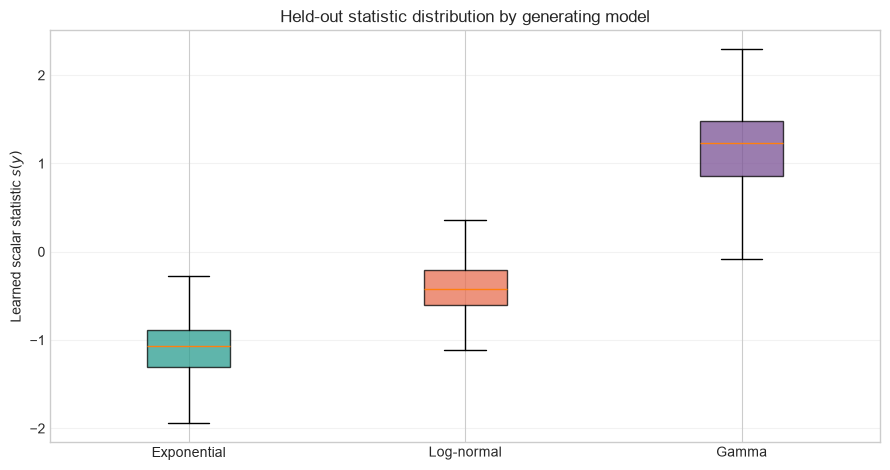

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.8))
box_data = [stat_original[true_test == model_id] for model_id in range(3)]
boxes = ax.boxplot(box_data, tick_labels=MODEL_NAMES, patch_artist=True, showfliers=False)
for patch, colour in zip(boxes["boxes"], colours):
    patch.set_facecolor(colour)
    patch.set_alpha(0.75)
ax.set_ylabel(r"Learned scalar statistic $s(y)$")
ax.set_title("Held-out statistic distribution by generating model")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 10. Save numerical outputs and interpret cautiously

The saved files contain the model, numerical metrics, and held-out statistics. Plots are displayed inside the notebook and are not saved as separate image files. The paired MSE tests invariance only to the specific transformation $y\mapsto2y$. Approximate equality under this transformation is useful evidence, but it is not enough to establish exact ancillarity for every parameter value or transformation.

The CNN also remains order-sensitive even though observations are i.i.d. A future robustness check should permute values within each sample and measure how much $s(y)$ and the class probabilities change.

In [39]:
held_out = pd.DataFrame({
    "row_id": test_idx,
    "model_id": true_test,
    "model": MODEL_NAMES[true_test],
    "theta": theta[test_idx],
    "statistic_original": stat_original,
    "statistic_doubled": stat_doubled,
    "predicted_model_original": class_original_pred,
    "predicted_model_doubled": class_doubled_pred,
})
held_out.to_csv(OUTPUT_DIR / "held_out_predictions.csv", index=False)
shared_cnn.save(OUTPUT_DIR / "shared_ancillary_cnn.keras")

output_files = sorted(
    path.name for path in OUTPUT_DIR.iterdir()
    if path.suffix in {".csv", ".keras"}
)
print("Saved numerical/model outputs:")
for name in output_files:
    print(" -", name)

print("\nInterpretation guide")
print("1. High accuracy for both views means the scalar retains model information.")
print("2. Low paired MSE/MAE and points near the diagonal mean invariance to doubling.")
print("3. Weak theta-statistic patterns and low probe R^2 mean less parameter leakage.")
print("4. None of these alone proves exact ancillarity.")

Saved numerical/model outputs:
 - headline_metrics.csv
 - held_out_predictions.csv
 - paired_statistic_similarity_by_model.csv
 - shared_ancillary_cnn.keras
 - theta_statistic_relationship.csv
 - training_history.csv

Interpretation guide
1. High accuracy for both views means the scalar retains model information.
2. Low paired MSE/MAE and points near the diagonal mean invariance to doubling.
3. Weak theta-statistic patterns and low probe R^2 mean less parameter leakage.
4. None of these alone proves exact ancillarity.
